# EBHI-SEG — segmentation validation comparison

## tl;dr

This notebook turns the **existing saved validation results** into an inspectable analysis:
13 methods, 372 images, six diagnostic categories, and four figures.

At the reviewed checkpoint, raw Lab K-means with **k=4, M0** has equal-category mean
Dice **0.7761**, while the all-foreground control has **0.7767**. This is a descriptive
validation result; it does not establish improvement over the control or answer the
classification question.

Prepared from repository commit
[`8192e3e09384b05fa760104436f3a2e226380ac3`](https://github.com/savitar393/ebhi-dip/tree/8192e3e09384b05fa760104436f3a2e226380ac3).
The tables and charts below are recomputed from CSV inputs. For deliberately replaced
experiment results, rerun every cell and update this checkpoint summary.

## Context & Methods

**Question:** which fixed segmentation candidate has the best validation foreground overlap,
and how does it compare with predicting every pixel as foreground?

### Key assumptions

- The frozen split is the cohort authority. Filename groups are provisional grouping keys,
  not verified patient identifiers.
- Otsu polarity, Lab cluster centers, and cluster foreground mapping were learned on training data.
  This notebook reads their recorded artifacts and validation scores.
- The reference foreground rule is `mask >= 128`.
- **M0:** raw mask. **M1:** retain 8-connected components of at least 16 pixels.
  **M2:** M1, then opening and closing with the 3×3 cross, one iteration each,
  `BORDER_REPLICATE`.
- The primary score is the mean of the six within-category mean image Dice scores.
  Each category has equal weight. IoU is averaged in the same way.
- Candidate ranking uses Dice rounded to four decimals, then IoU rounded to four decimals,
  then fewer postprocessing stages and fewer clusters for any remaining ties.
- Observed means are descriptive. No confidence intervals or statistical significance are inferred.

**Execution scope:** read saved results and metadata; do not refit models, regenerate the
split, process held-out test images, or overwrite experiment CSVs/models. Raw image files
and the pixel-sampling cache are not required.

### 1. Setup and parameters

Place this file under `ebhi-dip/notebooks/`. In VS Code, select the project's `.venv`
kernel and use **Restart Kernel → Run All**. Dependencies for this analysis are
`numpy`, `pandas`, `matplotlib`, and `ipykernel`.

The optional root override handles a kernel launched outside the project directory.
`EXPORT_FIGURES=False` keeps the analysis read-only; enabling it exports only figure PNGs
to `reports/figures/`.

In [1]:
%matplotlib inline

from pathlib import Path
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT_OVERRIDE = None  # Example: Path(r"D:\\ebhi-dip")
EXPORT_FIGURES = False
CHECKPOINT_COMMIT = "8192e3e09384b05fa760104436f3a2e226380ac3"
STAGES = ("M0", "M1", "M2")

def find_project_root(override=None):
    candidates = [Path(override).expanduser().resolve()] if override is not None else [Path.cwd(), *Path.cwd().parents]
    required = ("data/metadata/split_manifest.csv", "results/otsu_morph_val.csv", "results/kmeans_morph_val.csv")
    for candidate in candidates:
        if all((candidate / name).is_file() for name in required):
            return candidate
    raise FileNotFoundError("Put this notebook in ebhi-dip/notebooks/ or set PROJECT_ROOT_OVERRIDE to the repository root.")

ROOT = find_project_root(PROJECT_ROOT_OVERRIDE)
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 220, "font.size": 11,
    "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "figure.facecolor": "white",
})

def finish_figure(fig, filename):
    if EXPORT_FIGURES:
        destination = ROOT / "reports/figures" / filename
        destination.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(destination, bbox_inches="tight")
        print("Exported:", destination.name)
    plt.show()
    plt.close(fig)

display(pd.DataFrame({
    "component": ["Python", "NumPy", "pandas", "Matplotlib"],
    "analysis_runtime_version": [platform.python_version(), np.__version__, pd.__version__, matplotlib.__version__],
}))

,component,analysis_runtime_version
0,Python,3.12.14
1,NumPy,2.3.5
2,pandas,2.2.3
3,Matplotlib,3.10.8


## Data

### 2. Load the frozen cohort and committed result tables

K-means results use one row per image and method. Otsu results use one row per image
with separate columns for each variant. We retain these source formats and create
one common in-memory table for analysis.

In [2]:
source_files = {
    "split": ROOT / "data/metadata/split_manifest.csv",
    "split_checksum": ROOT / "data/metadata/split_manifest.sha256",
    "otsu": ROOT / "results/otsu_morph_val.csv",
    "kmeans": ROOT / "results/kmeans_morph_val.csv",
    "run": ROOT / "results/kmeans_morph_val_run.json",
    "otsu_config": ROOT / "configs/otsu_raw.json",
}
source_files.update({f"model_k{k}": ROOT / f"models/kmeans_lab_k{k}_mapped.json" for k in (2, 3, 4)})
for path in source_files.values():
    if not path.is_file():
        raise FileNotFoundError(path)

input_hashes_before = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in source_files.items()}
expected_split_sha = source_files["split_checksum"].read_text(encoding="utf-8").split()[0]
assert input_hashes_before["split"] == expected_split_sha, "Frozen split bytes changed."

split = pd.read_csv(source_files["split"], encoding="utf-8-sig", keep_default_na=False)
otsu = pd.read_csv(source_files["otsu"], encoding="utf-8-sig")
kmeans = pd.read_csv(source_files["kmeans"], encoding="utf-8-sig")
run = json.loads(source_files["run"].read_text(encoding="utf-8"))
otsu_config = json.loads(source_files["otsu_config"].read_text(encoding="utf-8"))
models = {k: json.loads(source_files[f"model_k{k}"].read_text(encoding="utf-8")) for k in (2, 3, 4)}

validation = split.loc[split["split"].eq("val")].copy()
categories = sorted(validation["category"].unique())
expected_methods = {f"k{k}_{stage}" for k in (2, 3, 4) for stage in STAGES} | {"all_foreground"}

assert split["sample_id"].is_unique
assert split.groupby("group_id")["split"].nunique().eq(1).all()
assert split.groupby("pixel_sha256")["split"].nunique().eq(1).all()
assert len(validation) == 372 and len(categories) == 6
assert len(otsu) == 372 and otsu["sample_id"].is_unique
assert len(kmeans) == 3720 and not kmeans.duplicated(["sample_id", "method"]).any()
assert set(kmeans["method"]) == expected_methods
assert kmeans["split"].eq("val").all()

def validate_result_cohort(table):
    assert table["sample_id"].is_unique
    assert set(table["sample_id"]) == set(validation["sample_id"])
    joined = table.merge(validation[["sample_id", "category", "group_id"]],
                         on="sample_id", how="left", suffixes=("", "_frozen"), validate="one_to_one")
    for column in ("category", "group_id"):
        assert joined[column].eq(joined[f"{column}_frozen"]).all(), f"Cohort metadata differs: {column}"

validate_result_cohort(otsu)
for _, table in kmeans.groupby("method", observed=True):
    validate_result_cohort(table)

assert run["evaluation_subset"] == "val" and run["split_sha256"] == expected_split_sha
assert run["image_count"] == 372 and run["result_row_count"] == len(kmeans)
assert run["reference_threshold"] == 128
assert otsu_config["split_sha256"] == expected_split_sha
assert otsu_config["polarity_selected_on"] == "train" and otsu_config["reference_threshold"] == 128
assert otsu["foreground_polarity"].eq(otsu_config["foreground_polarity"]).all()
for k, model in models.items():
    assert input_hashes_before[f"model_k{k}"] == run["model_sha256"][f"k{k}"], "Model differs from the recorded evaluation."
    assert model["fit_subset"] == "train" and model["split_sha256"] == expected_split_sha
    assert model["foreground_mapping"]["learned_on"] == "sampled_train_pixels"
    assert model["foreground_mapping"]["threshold"] == 0.5
    assert model["foreground_mapping"]["reference_threshold"] == 128

cohort_table = validation.groupby("category", observed=True).agg(
    validation_images=("sample_id", "size"), filename_groups=("group_id", "nunique")
).reindex(categories)
display(cohort_table)
print("Verified: 372 validation images, 10 K-means/control methods, and the frozen cohort and model artifacts.")

Verified: 372 validation images, 10 K-means/control methods, and the frozen cohort and model artifacts.


,validation_images,filename_groups
category,,
Adenocarcinoma,131,15
High-grade IN,20,5
Low-grade IN,107,21
Normal,10,3
Polyp,96,21
Serrated adenoma,8,2


### 3. Reconcile the two files and independently check the control

For an all-foreground prediction and reference foreground fraction \(r\),
\(\mathrm{Dice}=2r/(1+r)\) and \(\mathrm{IoU}=r\).
This explains why broad references can give a strong score to a constant prediction.
The duplicate control from the Otsu file is checked, then represented once in the combined table.

In [3]:
control = kmeans.loc[kmeans["method"].eq("all_foreground")].set_index("sample_id").sort_index()
otsu_control = otsu.set_index("sample_id").sort_index()
for metric in ("dice", "iou"):
    np.testing.assert_allclose(control[metric], otsu_control[f"all_foreground_{metric}"], rtol=0, atol=1e-12)

r = control["reference_foreground_fraction"].to_numpy()
assert np.isfinite(r).all() and ((r >= 0) & (r <= 1)).all()
np.testing.assert_allclose(control["dice"], 2 * r / (1 + r), rtol=0, atol=1e-12)
np.testing.assert_allclose(control["iou"], r, rtol=0, atol=1e-12)
np.testing.assert_allclose(control["predicted_foreground_fraction"], 1, rtol=0, atol=1e-12)
assert kmeans.groupby("sample_id")["reference_foreground_fraction"].nunique().eq(1).all()

pieces = [kmeans[["sample_id", "category", "group_id", "method", "dice", "iou"]].copy()]
for stage in STAGES:
    part = otsu[["sample_id", "category", "group_id", f"{stage}_dice", f"{stage}_iou"]].rename(
        columns={f"{stage}_dice": "dice", f"{stage}_iou": "iou"}
    ).copy()
    part["method"] = f"otsu_{stage}"
    pieces.append(part)

results = pd.concat(pieces, ignore_index=True)
assert len(results) == 372 * 13 and results["method"].nunique() == 13
assert not results.duplicated(["sample_id", "method"]).any()
assert np.isfinite(results[["dice", "iou"]].to_numpy()).all()
assert results[["dice", "iou"]].ge(0).all().all() and results[["dice", "iou"]].le(1).all().all()
print("Both controls agree per image; their scores match the independent coverage formulas.")

Both controls agree per image; their scores match the independent coverage formulas.


## Results

### 4. Recompute the primary score

First average image scores **within each category**, then average the six category means.
This preserves the project's selection rule even though category sizes differ.

In [4]:
category_scores = results.groupby(["method", "category"], observed=True)[["dice", "iou"]].mean()
summary = category_scores.groupby("method", observed=True).mean().rename(
    columns={"dice": "mean_category_dice", "iou": "mean_category_iou"}
)
summary["delta_dice_vs_control"] = summary["mean_category_dice"] - summary.loc["all_foreground", "mean_category_dice"]
summary["delta_iou_vs_control"] = summary["mean_category_iou"] - summary.loc["all_foreground", "mean_category_iou"]
summary = summary.sort_values(["mean_category_dice", "mean_category_iou"], ascending=False)

def method_label(method):
    if method == "all_foreground":
        return "All foreground"
    family, stage = method.split("_")
    return f"Otsu {stage}" if family == "otsu" else f"K-means k={family[1:]}, {stage}"

def ranking_key(method):
    row = summary.loc[method]
    stage = int(method.rsplit("M", 1)[1])
    k = int(method[1]) if method.startswith("k") else 0
    return (round(float(row["mean_category_dice"]), 4), round(float(row["mean_category_iou"]), 4), -stage, -k)

selected = {
    "Raw Otsu": "otsu_M0",
    "Processed Otsu": max(["otsu_M1", "otsu_M2"], key=ranking_key),
    "Raw K-means": max([f"k{k}_M0" for k in (2, 3, 4)], key=ranking_key),
    "Processed K-means": max([f"k{k}_{stage}" for k in (2, 3, 4) for stage in ("M1", "M2")], key=ranking_key),
    "Control": "all_foreground",
}
best_candidate = max([m for m in summary.index if m != "all_foreground"], key=ranking_key)
display(summary.style.format({column: "{:+.4f}" if column.startswith("delta") else "{:.4f}" for column in summary.columns}))
comparison = pd.DataFrame([
    {"comparator": name, "method": method, **summary.loc[method].to_dict()}
    for name, method in selected.items()
]).set_index("comparator")
display(comparison.style.format({column: "{:.4f}" for column in summary.columns}))

,mean_category_dice,mean_category_iou,delta_dice_vs_control,delta_iou_vs_control
method,,,,
all_foreground,0.7767,0.6477,+0.0000,+0.0000
k4_M0,0.7761,0.6427,-0.0006,-0.0050
k4_M1,0.7760,0.6426,-0.0007,-0.0051
k4_M2,0.7753,0.6425,-0.0013,-0.0053
k3_M2,0.7636,0.6275,-0.0131,-0.0202
k3_M1,0.7561,0.6159,-0.0205,-0.0319
k3_M0,0.7538,0.6128,-0.0228,-0.0349
k2_M2,0.7402,0.5975,-0.0365,-0.0503
k2_M1,0.7353,0.5892,-0.0414,-0.0585


,method,mean_category_dice,mean_category_iou,delta_dice_vs_control,delta_iou_vs_control
comparator,,,,,
Raw Otsu,otsu_M0,0.7232,0.5788,-0.0534,-0.0689
Processed Otsu,otsu_M2,0.7288,0.5886,-0.0479,-0.0591
Raw K-means,k4_M0,0.7761,0.6427,-0.0006,-0.0050
Processed K-means,k4_M1,0.7760,0.6426,-0.0007,-0.0051
Control,all_foreground,0.7767,0.6477,0.0000,0.0000


### 5. Overall validation comparison

Bars use the full Dice scale from 0 to 1. The following delta chart makes small
differences from the control visible without changing the absolute-score bar scale.

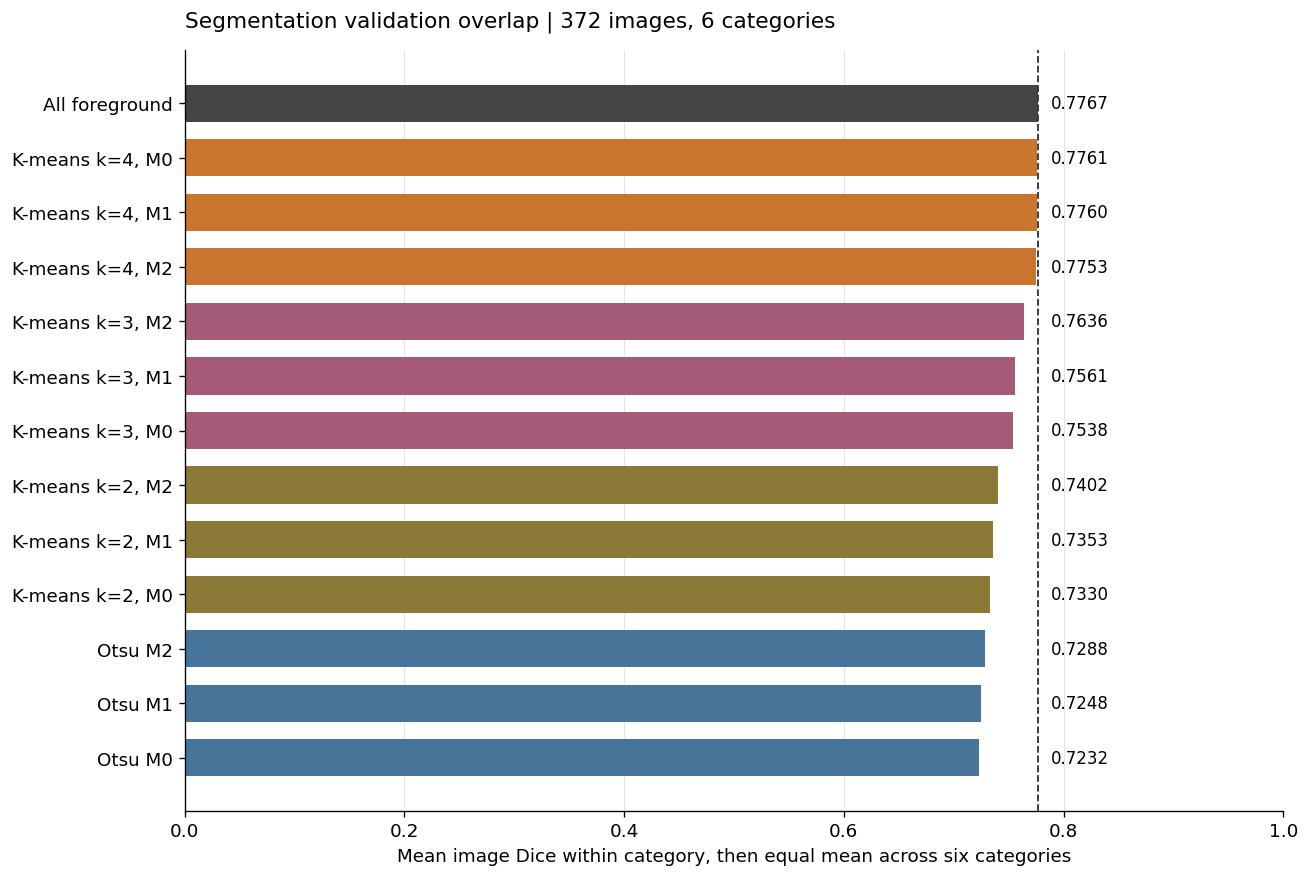

In [5]:
family_colors = {"otsu": "#47759A", "k2": "#8B7938", "k3": "#A45B78", "k4": "#C97530", "all": "#444444"}
def method_color(method):
    return family_colors["all" if method == "all_foreground" else method.split("_")[0]]

ordered = summary.sort_values("mean_category_dice", ascending=True)
fig, ax = plt.subplots(figsize=(10.8, 7.2), layout="constrained")
y_positions = np.arange(len(ordered))
ax.barh(y_positions, ordered["mean_category_dice"], color=[method_color(m) for m in ordered.index], height=0.68)
ax.set_yticks(y_positions, [method_label(m) for m in ordered.index])
for position, value in zip(y_positions, ordered["mean_category_dice"]):
    ax.text(max(value, float(summary.loc["all_foreground", "mean_category_dice"])) + 0.012, position, f"{value:.4f}", va="center", fontsize=10)
control_dice = float(summary.loc["all_foreground", "mean_category_dice"])
ax.axvline(control_dice, color="#333333", linewidth=1.1, linestyle="--")
ax.set_xlim(0, 1)
ax.set_xlabel("Mean image Dice within category, then equal mean across six categories")
ax.set_title("Segmentation validation overlap | 372 images, 6 categories", loc="left", pad=14)
ax.grid(axis="x", color="#E4E4E4", linewidth=0.6)
finish_figure(fig, "segmentation_validation_dice.png")

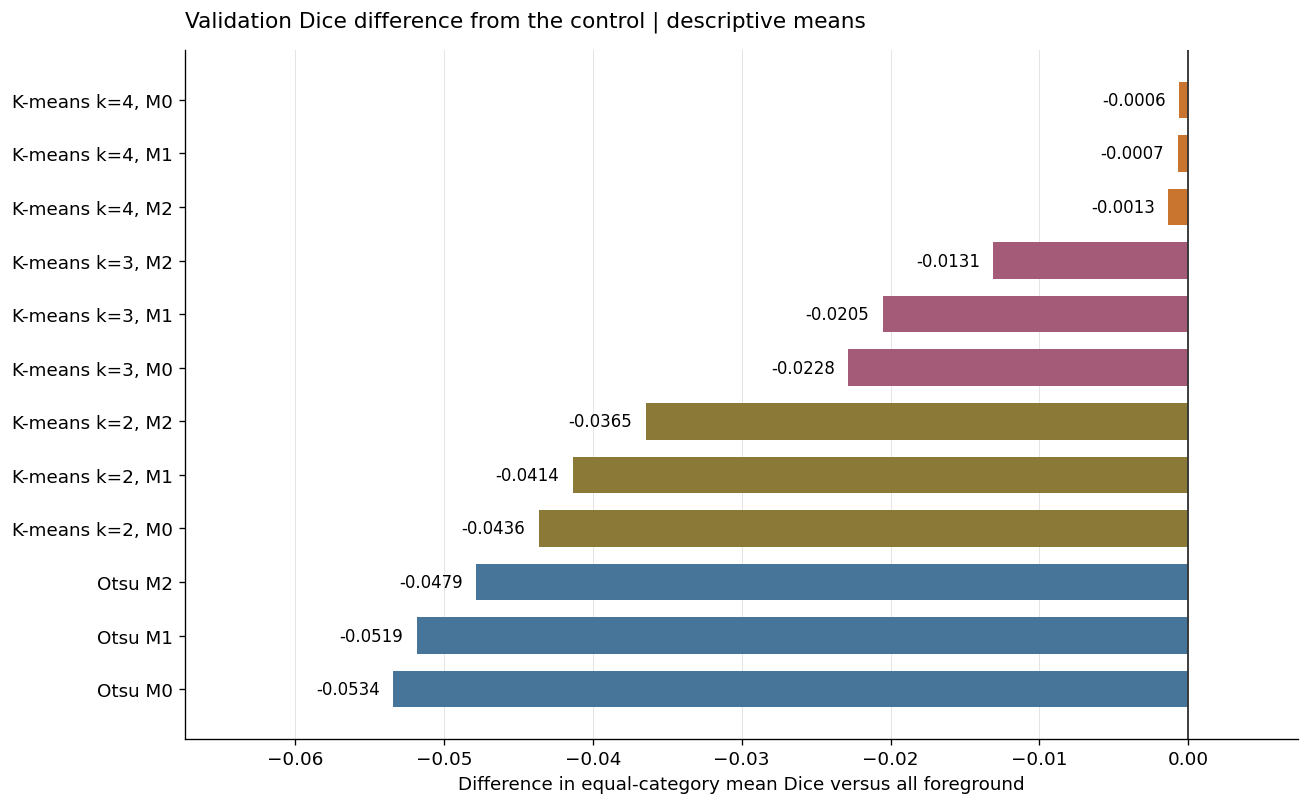

In [6]:
delta = summary.drop(index="all_foreground").sort_values("delta_dice_vs_control")
fig, ax = plt.subplots(figsize=(10.8, 6.6), layout="constrained")
y_positions = np.arange(len(delta))
ax.barh(y_positions, delta["delta_dice_vs_control"], color=[method_color(m) for m in delta.index], height=0.68)
ax.set_yticks(y_positions, [method_label(m) for m in delta.index])
for position, value in zip(y_positions, delta["delta_dice_vs_control"]):
    offset = -0.0009 if value < 0 else 0.0009
    ax.text(value + offset, position, f"{value:+.4f}", va="center", ha="right" if value < 0 else "left", fontsize=10)
ax.axvline(0, color="#333333", linewidth=1.1)
ax.set_xlim(min(float(delta["delta_dice_vs_control"].min()) - 0.014, -0.01), max(float(delta["delta_dice_vs_control"].max()) + 0.008, 0.006))
ax.set_xlabel("Difference in equal-category mean Dice versus all foreground")
ax.set_title("Validation Dice difference from the control | descriptive means", loc="left", pad=14)
ax.grid(axis="x", color="#E4E4E4", linewidth=0.6)
finish_figure(fig, "segmentation_validation_delta.png")

In [7]:
best_score = summary.loc[best_candidate]
control_score = summary.loc["all_foreground"]
delta_best = float(best_score["mean_category_dice"] - control_score["mean_category_dice"])
relation = "above" if delta_best > 0 else "below" if delta_best < 0 else "equal to"
display(Markdown(
    f"**Computed interpretation.** The best image-dependent candidate is **{method_label(best_candidate)}**, "
    f"with mean Dice **{best_score['mean_category_dice']:.4f}** and mean IoU **{best_score['mean_category_iou']:.4f}**. "
    f"Its Dice is **{abs(delta_best):.4f} {relation}** the control. "
    "This comparison describes validation means; it does not establish statistical significance."
))

**Computed interpretation.** The best image-dependent candidate is **K-means k=4, M0**, with mean Dice **0.7761** and mean IoU **0.6427**. Its Dice is **0.0006 below** the control. This comparison describes validation means; it does not establish statistical significance.

### 6. Category-level overlap

Each cell is a within-category mean image Dice. The sample count is shown next to
the category. This view supports diagnosis; the project uses a single global configuration
per candidate, rather than selecting a different model using a sample's true category.

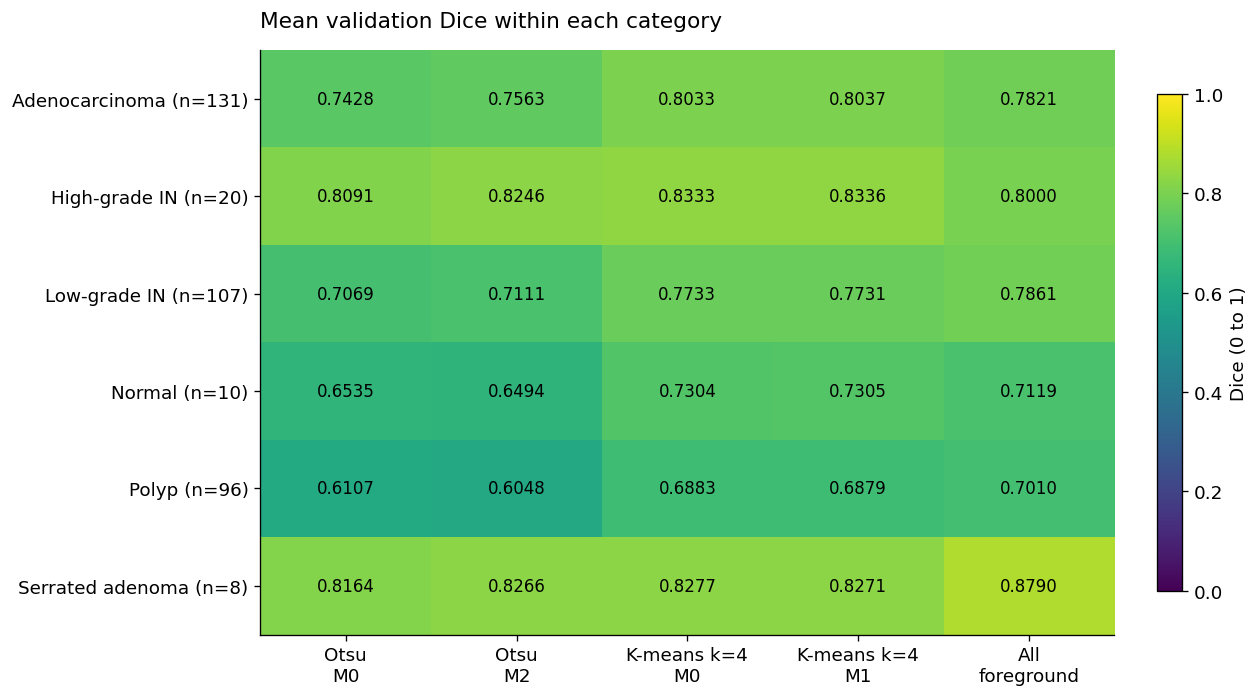

In [8]:
selected_methods = list(selected.values())
matrix = category_scores["dice"].unstack("method").reindex(index=categories, columns=selected_methods)
fig, ax = plt.subplots(figsize=(10.4, 5.7), layout="constrained")
heatmap = ax.imshow(matrix.to_numpy(), cmap="viridis", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(np.arange(len(selected_methods)), ["Otsu\nM0", "Otsu\n" + selected["Processed Otsu"].split("_")[-1],
    method_label(selected["Raw K-means"]).replace(", ", "\n"),
    method_label(selected["Processed K-means"]).replace(", ", "\n"), "All\nforeground"])
ax.set_yticks(np.arange(len(categories)), [f"{c} (n={int(cohort_table.loc[c, 'validation_images'])})" for c in categories])
for row_index in range(len(categories)):
    for column_index in range(len(selected_methods)):
        value = float(matrix.iloc[row_index, column_index])
        ax.text(column_index, row_index, f"{value:.4f}", ha="center", va="center", color="black" if value >= 0.60 else "white", fontsize=10)
ax.set_title("Mean validation Dice within each category", loc="left", pad=14)
fig.colorbar(heatmap, ax=ax, label="Dice (0 to 1)", shrink=0.85)
finish_figure(fig, "segmentation_validation_category_heatmap.png")

### 7. Reference foreground coverage

These are reference foreground fractions recorded in the K-means validation CSV, one
observation per validation image. They describe annotated area, not segmentation accuracy.
Large foreground fractions make the all-foreground control particularly important.

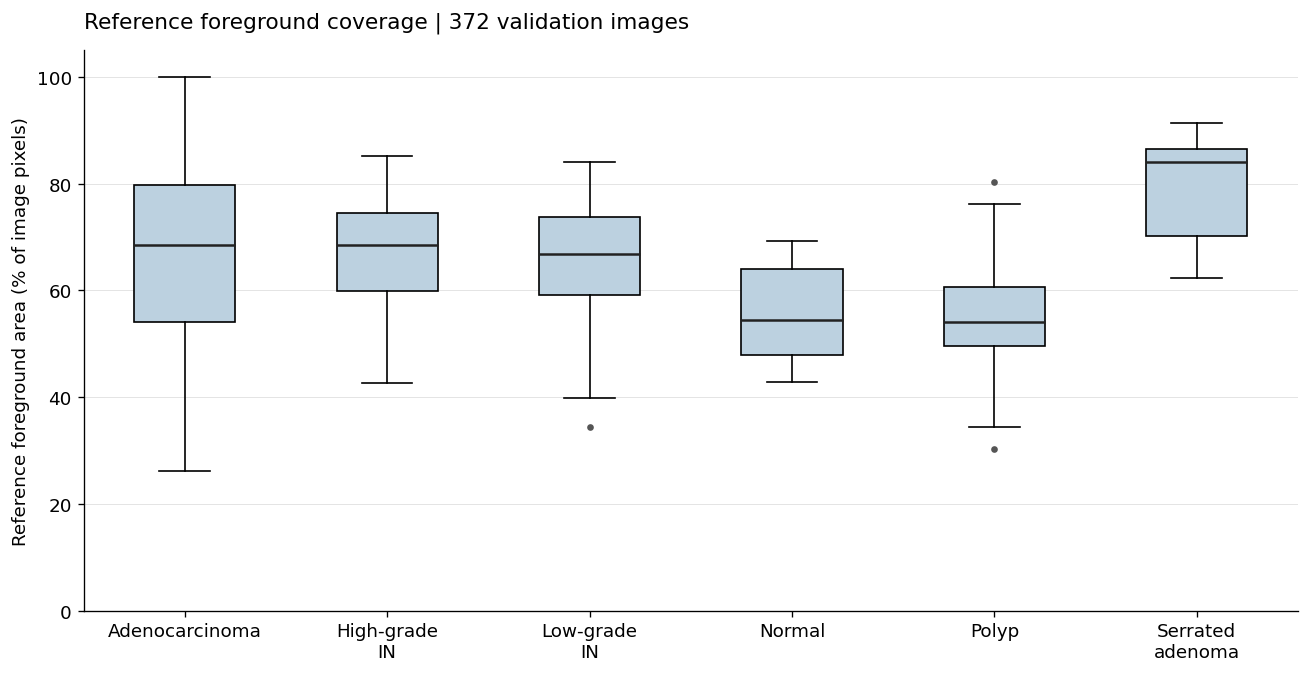

,count,min,median,mean,max
category,,,,,
Adenocarcinoma,131,26.10,68.60,66.46,100.00
High-grade IN,20,42.63,68.44,67.29,85.24
Low-grade IN,107,34.42,66.92,65.44,84.04
Normal,10,42.87,54.40,55.77,69.22
Polyp,96,30.26,54.15,54.64,80.39
Serrated adenoma,8,62.35,84.15,79.04,91.38


In [9]:
coverage = control.reset_index()[["sample_id", "category", "reference_foreground_fraction"]].copy()
coverage["reference_foreground_percent"] = 100 * coverage["reference_foreground_fraction"]
fig, ax = plt.subplots(figsize=(10.8, 5.5), layout="constrained")
values = [coverage.loc[coverage["category"].eq(c), "reference_foreground_percent"].to_numpy() for c in categories]
boxplot = ax.boxplot(values, tick_labels=[c.replace(" ", "\n") for c in categories], patch_artist=True,
    medianprops={"color": "#222222", "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": "#555555", "markeredgecolor": "#555555"})
for box in boxplot["boxes"]:
    box.set_facecolor("#BCD1E0")
ax.set_ylim(0, 105)
ax.set_ylabel("Reference foreground area (% of image pixels)")
ax.set_title("Reference foreground coverage | 372 validation images", loc="left", pad=14)
ax.grid(axis="y", color="#E4E4E4", linewidth=0.6)
finish_figure(fig, "validation_reference_foreground_coverage.png")
display(coverage.groupby("category", observed=True)["reference_foreground_percent"].agg(["count", "min", "median", "mean", "max"]).round(2))

### 8. Provenance and the source line-ending issue

The split and JSON model fingerprints are checked strictly above. The recorded helper
fingerprints need a separate diagnostic: at the reviewed commit, the exact Git LF
source bytes differ from the recorded hash, while their CRLF equivalents match.

This identifies a portability issue in the existing source-code guards. It does not
indicate changed centers or altered numeric result rows. This notebook reports the evidence;
it does not replace hashes in historical artifacts or rerun image inference.

In [10]:
def source_hash_diagnostic(relative_path, recorded_sha):
    path = ROOT / relative_path
    if not path.is_file():
        return {"source": relative_path, "exact_match": False, "diagnosis": "Source moved or unavailable; inspect original checkpoint"}
    data = path.read_bytes()
    if hashlib.sha256(data).hexdigest() == recorded_sha:
        diagnosis = "Exact source-byte match"
        exact_match = True
    else:
        lf = data.replace(b"\r\n", b"\n")
        alternatives = {"LF": lf, "CRLF": lf.replace(b"\n", b"\r\n")}
        matches = [name for name, candidate in alternatives.items() if hashlib.sha256(candidate).hexdigest() == recorded_sha]
        diagnosis = "Recorded hash matches " + ", ".join(matches) + " line endings" if matches else "Mismatch needs investigation beyond line endings"
        exact_match = False
    return {"source": relative_path, "exact_match": exact_match, "diagnosis": diagnosis}

diagnostics = pd.DataFrame([
    source_hash_diagnostic("kmeans_prediction.py", run["prediction_helper_sha256"]),
    source_hash_diagnostic("postprocessing.py", run["postprocessing_helper_sha256"]),
])
display(diagnostics)
display(pd.DataFrame([
    {"input": path.relative_to(ROOT).as_posix(), "bytes": path.stat().st_size, "sha256_prefix": input_hashes_before[name][:20]}
    for name, path in source_files.items()
]))

,source,exact_match,diagnosis
0,kmeans_prediction.py,False,Recorded hash matches CRLF line endings
1,postprocessing.py,False,Recorded hash matches CRLF line endings


,input,bytes,sha256_prefix
0,data/metadata/split_manifest.csv,575716,ceeba8e282f77cdb78a9
1,data/metadata/split_manifest.sha256,85,adec18cba100dd7bb0d4
2,results/otsu_morph_val.csv,81575,17f24293a33b1fefe78a
3,results/kmeans_morph_val.csv,527037,b9f883614796725589ec
4,results/kmeans_morph_val_run.json,1066,5ecd034b88d84ecab74b
5,configs/otsu_raw.json,466,dcd8b0867f50f10912fc
6,models/kmeans_lab_k2_mapped.json,2390,026a125a21a32bfef19f
7,models/kmeans_lab_k3_mapped.json,2549,d50bcf44f4ec87b69549
8,models/kmeans_lab_k4_mapped.json,2715,0531165e8f29433738e8


## Takeaways

At this checkpoint, retain the four global comparators for subsequent analysis and
use the raw k=4 candidate as the primary image-dependent mask source. The all-foreground
control remains part of the segmentation comparison.

Morphological descriptors should describe **predicted binary regions**. Their biological
interpretation and their contribution to classification require further evidence.

The next research steps are the planned color/texture and morphology feature extraction,
then the A/B/C classification comparison. Final held-out evaluation comes after those
choices are fixed. This notebook contributes no new held-out test scores.

For the notebook migration: keep computation in reusable Python modules, call those
functions from short notebook cells, and retain JSON/CSV artifacts as the handoff between stages.
Keep the original scripts available until numerical parity and provenance handling have been checked.

In [11]:
input_hashes_after = {name: hashlib.sha256(path.read_bytes()).hexdigest() for name, path in source_files.items()}
assert input_hashes_after == input_hashes_before, "An input artifact changed while running this notebook."
assert set(results["sample_id"]) == set(validation["sample_id"])
print("Completed: 13 methods, 372 validation images, 4 figures; experiment inputs are unchanged.")

Completed: 13 methods, 372 validation images, 4 figures; experiment inputs are unchanged.
